# Progress 3: Diferensiasi, Pemodelan SARIMA & RegARIMA, Diagnostik Residual, dan Evaluasi Validasi

*Daffa Muhammad Khrisadi / 24083010062 / Analisis Deret Waktu A*

---

### Ruang Lingkup Progress 3
Notebook ini melanjutkan **Progress 1** (eksplorasi data, uji ketidakstasioneran data level, dan tiga *baseline* awal) serta **Progress 2** (draf poster 50% hingga bagian 04). Fokus utama pada tahap ini adalah membangun dan menguji **model statistik utama (SARIMA & RegARIMA)** secara ketat tanpa kebocoran data (*no data leakage*):

1. **Transformasi & Diferensiasi ($d, D, s=4$):** Menguji stasioneritas pasca-diferensiasi pada *Training Set* (`2010-Q1`–`2022-Q3`, 51 observasi) menggunakan **ADF** dan **KPSS**.
2. **Identifikasi Orde Box-Jenkins:** Membaca plot **ACF** dan **PACF** deret terdiferensiasi untuk merumuskan kandidat model yang parsimoni.
3. **Estimasi & Seleksi Model SARIMA & RegARIMA:** Membandingkan kandidat pada skala asli vs skala logaritma, menguji tiga rezim diferensiasi, serta menguji signifikansi variabel eksogen kalender `hari_ramadan_idul_fitri`.
4. **Uji Diagnostik Residual:** Memvalidasi asumsi *white noise* (**Ljung-Box**), normalitas (**Shapiro-Wilk** & **Jarque-Bera**), dan homoskedastisitas (**Engle's ARCH-LM**).
5. **Evaluasi pada Validation Set (`2022-Q4`–`2024-Q3`, 8 triwulan):** Membandingkan kinerja peramalan 8 langkah ke depan menggunakan **RMSE, MAE, MAPE, sMAPE, dan MASE** terhadap ketiga *baseline* awal.

> **Catatan Integritas Eksperimen:** *Test Set* (`2024-Q4`–`2026-Q3`, 8 triwulan) **tetap dikunci** (*strict holdout*) dan tidak digunakan untuk estimasi maupun pemilihan model pada tahap ini. Evaluasi akhir pada *Test Set* akan dilakukan setelah model pembanding **SVR-RBF** selesai dibangun pada tahap berikutnya.

---
## 1. Pemuatan Data, Pembagian Kronologis, & Rekapitulasi Baseline (+ MASE)

Pembagian data mempertahankan skema kronologis yang identik dengan Progress 1 (`Training = 51`, `Validation = 8`, `Test = 8` dikunci). Sebagai pelengkap metrik evaluasi sesuai panduan proyek, metrik **MASE (*Mean Absolute Scaled Error*)** ditambahkan dengan penyebut berupa kesalahan absolut rata-rata *in-sample* **Seasonal Naive ($s=4$)** pada *Training Set*:

$$\text{MASE} = \frac{\text{MAE}_{\text{forecast}}}{\frac{1}{N_{\text{train}} - 4} \sum_{t=5}^{N_{\text{train}}} |Y_t - Y_{t-4}|}$$

Nilai $\text{MASE} < 1$ menandakan model lebih akurat dibandingkan patokan naif musiman tahunan pada data latih.

In [1]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.03)

# Palet warna konsisten antar grafik
PALETTE = {
    'actual': '#111111',
    'train': '#4a5568',
    'sarima_best': '#1f77b4',
    'sarima_alt1': '#17becf',
    'sarima_alt2': '#2b5c8f',
    'regarima': '#d62728',
    'naive': '#9467bd',
    'snaive': '#ff7f0e',
    'ols': '#2ca02c',
}

# 1. Muat dataset & pembagian kronologis identik dengan Progress 1
DATA_PATH = pathlib.Path('../data/pdb_industri_makanan_minuman_bps.csv')
df = pd.read_csv(DATA_PATH)
df['tanggal'] = pd.to_datetime(df['tanggal'])

N_VAL = 8
N_TEST = 8
N_TRAIN = len(df) - N_VAL - N_TEST

train_df = df.iloc[:N_TRAIN].copy()
val_df = df.iloc[N_TRAIN:N_TRAIN + N_VAL].copy()
test_df = df.iloc[N_TRAIN + N_VAL:].copy()  # DIKUNCI — tidak disentuh untuk pemodelan

y_train = train_df['pdb_mamin_adhk_miliar_rp'].values
y_val = val_df['pdb_mamin_adhk_miliar_rp'].values
log_y_train = np.log(y_train)

exog_train = train_df[['hari_ramadan_idul_fitri']].copy()
exog_val = val_df[['hari_ramadan_idul_fitri']].copy()

# Penyebut MASE: MAE in-sample Seasonal Naive (s = 4) murni pada Training Set
MASE_DENOM = float(np.mean(np.abs(y_train[4:] - y_train[:-4])))

print(f"Training Set   : {train_df['periode'].iloc[0]} s.d. {train_df['periode'].iloc[-1]} ({len(train_df)} observasi)")
print(f"Validation Set : {val_df['periode'].iloc[0]} s.d. {val_df['periode'].iloc[-1]} ({len(val_df)} observasi)")
print(f"Test Set       : {test_df['periode'].iloc[0]} s.d. {test_df['periode'].iloc[-1]} ({len(test_df)} observasi — DIKUNCI)")
print(f"Penyebut MASE (in-sample Seasonal Naive s=4 pada Train): {MASE_DENOM:,.2f} Miliar Rp")


def evaluate_forecast(y_true: np.ndarray, y_pred: np.ndarray, mase_denom: float = MASE_DENOM) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    smape = float(np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100)
    mase = mae / mase_denom
    return {
        'RMSE (Miliar Rp)': round(rmse, 2),
        'MAE (Miliar Rp)': round(mae, 2),
        'MAPE (%)': round(mape, 3),
        'sMAPE (%)': round(smape, 3),
        'MASE': round(mase, 3),
    }


# 2. Rekapitulasi 3 Baseline Progress 1 (kini dilengkapi MASE)
horizon_val = len(y_val)
pred_val_naive = np.repeat(y_train[-1], horizon_val)
pred_val_snaive = np.tile(y_train[-4:], int(np.ceil(horizon_val / 4)))[:horizon_val]

def make_trend_seasonal_matrix(sub_df: pd.DataFrame, start_t: int) -> np.ndarray:
    t_idx = np.arange(start_t, start_t + len(sub_df), dtype=float)
    q2 = (sub_df['triwulan'].values == 2).astype(float)
    q3 = (sub_df['triwulan'].values == 3).astype(float)
    q4 = (sub_df['triwulan'].values == 4).astype(float)
    return np.column_stack([t_idx, q2, q3, q4])

ols_baseline = LinearRegression().fit(make_trend_seasonal_matrix(train_df, 0), log_y_train)
pred_val_ols = np.exp(ols_baseline.predict(make_trend_seasonal_matrix(val_df, len(train_df))))

baseline_recap = pd.DataFrame([
    {'Model': 'Baseline 1 — Naive (Last Value)', **evaluate_forecast(y_val, pred_val_naive)},
    {'Model': 'Baseline 2 — Seasonal Naive (s = 4)', **evaluate_forecast(y_val, pred_val_snaive)},
    {'Model': 'Baseline 3 — Log-Linear + Seasonal OLS', **evaluate_forecast(y_val, pred_val_ols)},
])

print('\n=== Rekapitulasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===')
display(baseline_recap)

Training Set   : 2010-Q1 s.d. 2022-Q3 (51 observasi)
Validation Set : 2022-Q4 s.d. 2024-Q3 (8 observasi)
Test Set       : 2024-Q4 s.d. 2026-Q3 (8 observasi — DIKUNCI)
Penyebut MASE (in-sample Seasonal Naive s=4 pada Train): 9,277.56 Miliar Rp

=== Rekapitulasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===


,Model,RMSE (Miliar Rp),MAE (Miliar Rp),MAPE (%),sMAPE (%),MASE
0,Baseline 1 — Naive (Last Value),9407.24,7475.00,3.387,3.474,0.806
1,Baseline 2 — Seasonal Naive (s = 4),17789.37,16540.02,7.627,7.977,1.783
2,Baseline 3 — Log-Linear + Seasonal OLS,23407.15,22724.00,10.481,9.935,2.449


**Analisis Rekapitulasi Baseline & Patokan MASE:**
- Pembagian kronologis terverifikasi identik dengan Progress 1 dan 2: 51 observasi latih (`2010-Q1`–`2022-Q3`), 8 observasi validasi (`2022-Q4`–`2024-Q3`), dan 8 observasi uji (`2024-Q4`–`2026-Q3`) yang tetap dikunci.
- Penyebut MASE dari kesalahan *in-sample* Seasonal Naive ($s=4$) pada *Training Set* sebesar **9.277,56 miliar rupiah** mencerminkan rata-rata pertumbuhan tahunan PDB riil antar-triwulan yang sama.
- Pada metrik MASE, **Naive** mencapai `0,806` (semata-mata terbantu posisi puncak musiman akhir data latih di `2022-Q3`), sedangkan **Seasonal Naive** (`1,783`) dan **Log-Linear + Seasonal OLS** (`2,449`) masih di atas `1,0`. Model SARIMA/RegARIMA yang layak harus mengungguli ketiga *baseline* ini secara substansial (`RMSE < 9.407,24` dan `MASE << 0,806`).

---
## 2. Transformasi Logaritma, Diferensiasi, & Pembuktian Stasioneritas

Pada Progress 1 terbukti bahwa baik deret level asli $Y_t$ maupun transformasi logaritma $\ln(Y_t)$ **belum stasioner** (`ADF p > 0,05` dan `KPSS p = 0,01`). Di tahap ini, seluruh kombinasi diferensiasi non-musiman ($d \in \{0, 1\}$) dan musiman kuartalan ($D \in \{0, 1\}, s = 4$) diuji murni pada *Training Set*:

- **Diferensiasi pertama ($d=1, D=0$):** $\Delta \ln(Y_t) = \ln(Y_t) - \ln(Y_{t-1})$ (aproksimasi laju pertumbuhan *q-to-q*).
- **Diferensiasi musiman ($d=0, D=1, s=4$):** $\Delta_4 \ln(Y_t) = \ln(Y_t) - \ln(Y_{t-4})$ (aproksimasi laju pertumbuhan tahunan *y-o-y*).
- **Diferensiasi ganda ($d=1, D=1, s=4$):** $\Delta\Delta_4 \ln(Y_t) = \Delta_4 \ln(Y_t) - \Delta_4 \ln(Y_{t-1})$ (perubahan laju pertumbuhan *y-o-y*).

=== Uji Stasioneritas Sebelum & Sesudah Diferensiasi pada Training Set (2010-Q1 s.d. 2022-Q3) ===


,Deret Uji (Training Set),Skala,n,Std,ADF Stat (c),ADF p (c),ADF p (ct),KPSS Stat (c),KPSS p (c),Kesimpulan (α = 5%)
0,Data Asli Y_t (Level),Asli,51,37218.3224,-0.4254,0.9058,0.0571,1.1251,0.0100,TIDAK STASIONER
1,"ΔY_t (d=1, D=0)",Asli,50,5559.9840,-1.8449,0.3584,0.6879,0.1402,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
2,"Δ4Y_t (d=0, D=1, s=4)",Asli,47,4221.3969,-1.9048,0.3298,0.8541,0.2042,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
3,"ΔΔ4Y_t (d=1, D=1, s=4)",Asli,46,3384.4307,-6.3534,0.0000,0.0000,0.0384,0.1000,STASIONER (ADF & KPSS)
4,Logaritma ln(Y_t) (Level),Log,51,0.2640,-1.8490,0.3564,0.9946,1.1192,0.0100,TIDAK STASIONER
5,"Δln(Y_t) (d=1, D=0)",Log,50,0.0370,-1.1178,0.7079,0.5041,0.3202,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
6,"Δ4ln(Y_t) (d=0, D=1, s=4)",Log,47,0.0325,-1.1546,0.6928,0.0375,0.5954,0.0231,TIDAK STASIONER
7,"ΔΔ4ln(Y_t) (d=1, D=1, s=4)",Log,46,0.0230,-6.3315,0.0000,0.0000,0.0387,0.1000,STASIONER (ADF & KPSS)


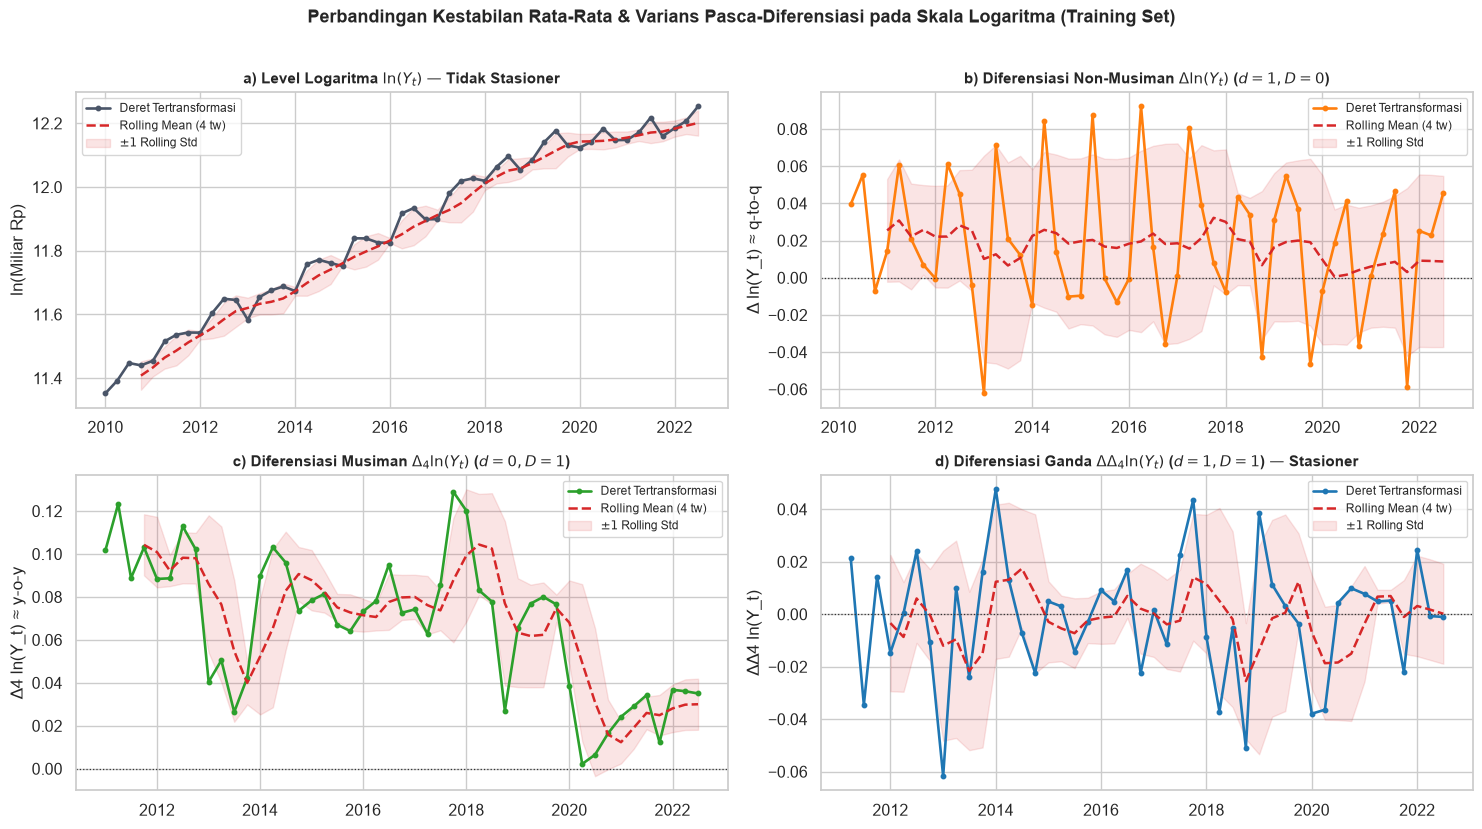

In [2]:
s_orig = pd.Series(y_train, index=train_df['tanggal'])
s_log = pd.Series(log_y_train, index=train_df['tanggal'])

diff_candidates = [
    ('Data Asli Y_t (Level)', 'Asli', 0, 0, s_orig),
    ('ΔY_t (d=1, D=0)', 'Asli', 1, 0, s_orig.diff(1).dropna()),
    ('Δ4Y_t (d=0, D=1, s=4)', 'Asli', 0, 1, s_orig.diff(4).dropna()),
    ('ΔΔ4Y_t (d=1, D=1, s=4)', 'Asli', 1, 1, s_orig.diff(4).diff(1).dropna()),
    ('Logaritma ln(Y_t) (Level)', 'Log', 0, 0, s_log),
    ('Δln(Y_t) (d=1, D=0)', 'Log', 1, 0, s_log.diff(1).dropna()),
    ('Δ4ln(Y_t) (d=0, D=1, s=4)', 'Log', 0, 1, s_log.diff(4).dropna()),
    ('ΔΔ4ln(Y_t) (d=1, D=1, s=4)', 'Log', 1, 1, s_log.diff(4).diff(1).dropna()),
]

stationarity_rows = []
for label, scale, d_ord, D_ord, ser in diff_candidates:
    arr = ser.values
    adf_stat_c, adf_p_c, _, _, _, _ = adfuller(arr, regression='c', autolag='AIC')
    adf_stat_ct, adf_p_ct, _, _, _, _ = adfuller(arr, regression='ct', autolag='AIC')
    kpss_stat_c, kpss_p_c, _, _ = kpss(arr, regression='c', nlags='auto')
    if (adf_p_c < 0.05) and (kpss_p_c >= 0.05):
        verdict = 'STASIONER (ADF & KPSS)'
    elif (adf_p_c >= 0.05) and (kpss_p_c >= 0.05):
        verdict = 'PARSIAL (KPSS lolos, ADF belum)'
    else:
        verdict = 'TIDAK STASIONER'
    stationarity_rows.append({
        'Deret Uji (Training Set)': label,
        'Skala': scale,
        'n': len(arr),
        'Std': round(float(np.std(arr, ddof=1)), 4),
        'ADF Stat (c)': round(float(adf_stat_c), 4),
        'ADF p (c)': round(float(adf_p_c), 4),
        'ADF p (ct)': round(float(adf_p_ct), 4),
        'KPSS Stat (c)': round(float(kpss_stat_c), 4),
        'KPSS p (c)': round(float(kpss_p_c), 4),
        'Kesimpulan (α = 5%)': verdict,
    })

stationarity_df = pd.DataFrame(stationarity_rows)
print('=== Uji Stasioneritas Sebelum & Sesudah Diferensiasi pada Training Set (2010-Q1 s.d. 2022-Q3) ===')
display(stationarity_df)

# Visualisasi transformasi & diferensiasi pada skala logaritma
plot_series = [
    (r'a) Level Logaritma $\ln(Y_t)$ — Tidak Stasioner', s_log, 'ln(Miliar Rp)', '#4a5568'),
    (r'b) Diferensiasi Non-Musiman $\Delta\ln(Y_t)$ ($d=1, D=0$)', s_log.diff(1).dropna(), 'Δ ln(Y_t) ≈ q-to-q', '#ff7f0e'),
    (r'c) Diferensiasi Musiman $\Delta_4\ln(Y_t)$ ($d=0, D=1$)', s_log.diff(4).dropna(), 'Δ4 ln(Y_t) ≈ y-o-y', '#2ca02c'),
    (r'd) Diferensiasi Ganda $\Delta\Delta_4\ln(Y_t)$ ($d=1, D=1$) — Stasioner', s_log.diff(4).diff(1).dropna(), 'ΔΔ4 ln(Y_t)', '#1f77b4'),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 8.2))
for ax, (title, ser, ylabel, color) in zip(axes.flat, plot_series):
    roll_m = ser.rolling(window=4).mean()
    roll_s = ser.rolling(window=4).std()
    ax.plot(ser.index, ser.values, color=color, lw=1.9, marker='o', ms=3.2, label='Deret Tertransformasi')
    ax.plot(ser.index, roll_m.values, color='#d62728', lw=1.8, ls='--', label='Rolling Mean (4 tw)')
    ax.fill_between(ser.index, roll_m - roll_s, roll_m + roll_s, color='#d62728', alpha=0.12, label=r'$\pm 1$ Rolling Std')
    if 'Level' not in title:
        ax.axhline(0, color='#333333', lw=0.9, ls=':')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_ylabel(ylabel)
    ax.legend(loc='best', fontsize=8.5)

plt.suptitle('Perbandingan Kestabilan Rata-Rata & Varians Pasca-Diferensiasi pada Skala Logaritma (Training Set)', fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Analisis Hasil Uji Stasioneritas Pasca-Diferensiasi:**
1. **Diferensiasi Ganda ($d=1, D=1, s=4$):** Baik $\Delta\Delta_4 Y_t$ maupun $\Delta\Delta_4 \ln(Y_t)$ secara tegas dinyatakan **STASIONER** oleh kedua uji pada $\alpha = 5\%$ — pada skala logaritma, `ADF Stat = -6,3315` (`p < 0,0001`) menolak keberadaan akar unit, sementara `KPSS Stat = 0,0387` (`p = 0,1000`) gagal menolak stasioneritas dengan simpangan baku terkecil (`0,0230`).
2. **Diferensiasi Non-Musiman Tunggal ($d=1, D=0$):** Pada $\Delta \ln(Y_t)$, uji KPSS telah lolos (`p = 0,1000`), sedangkan uji ADF belum menolak hipotesis nol (`p = 0,7079`). Panel (b) memperlihatkan rata-rata bergulir relatif datar, tetapi fluktuasi kuartalan tetap berulang secara teratur setiap 4 triwulan — menandakan bahwa pola musiman kuat tersebut dapat ditangani baik melalui diferensiasi musiman ($D=1$) maupun melalui komponen AR musiman stasioner ($P \ge 1$) dengan *drift*.
3. **Diferensiasi Musiman Tunggal ($d=0, D=1, s=4$):** Panel (c) menunjukkan $\Delta_4 \ln(Y_t)$ (laju pertumbuhan tahunan *y-o-y*) berfluktuasi di sekitar kisaran positif 5%–10% sebelum melandai pasca-2020 (sehingga ADF dengan tren `ct` sudah signifikan `p = 0,0375`, sedangkan ADF `c` belum karena persistensi AR(1) yang tinggi).
4. **Implikasi Pemodelan:** Sesuai praktik terbaik Box-Jenkins dan Hyndman–Athanasopoulos (FPP3), nilai **AIC/AICc/BIC tidak boleh dibandingkan lintas orde diferensiasi $(d, D)$ yang berbeda**. Oleh karena itu, pada Bagian 3–4 kita mengidentifikasi dan menyeleksi kandidat terbaik di **dalam masing-masing tiga rezim diferensiasi** ($d=1, D=0$; $d=0, D=1$; dan $d=1, D=1$) pada skala logaritma, lalu membandingkan performa antar-rezim secara adil di *Validation Set*!

---
## 3. Identifikasi Kandidat Orde SARIMA via ACF & PACF Pasca-Diferensiasi

Untuk menentukan kandidat orde non-musiman $(p, q)$ dan musiman $(P, Q)_4$, kita memeriksa plot **ACF** dan **PACF** hingga lag ke-16 pada ketiga deret terdiferensiasi skala logaritma dari *Training Set*.

Rezim 1: Δln(Y_t) (d=1, D=0) (n=50, batas 95% = ±0.277)
  ACF signifikan  : lag 2 (-0.501), lag 4 (+0.753), lag 6 (-0.445), lag 8 (+0.684), lag 10 (-0.512), lag 12 (+0.551)
  PACF signifikan : lag 2 (-0.531), lag 3 (-0.466), lag 4 (+0.551)

Rezim 2: Δ4ln(Y_t) (d=0, D=1, s=4) (n=47, batas 95% = ±0.286)
  ACF signifikan  : lag 1 (+0.730), lag 2 (+0.461), lag 6 (+0.338)
  PACF signifikan : lag 1 (+0.730), lag 5 (+0.361), lag 7 (-0.336)

Rezim 3: ΔΔ4ln(Y_t) (d=1, D=1, s=4) (n=46, batas 95% = ±0.289)
  ACF signifikan  : lag 4 (-0.382), lag 6 (+0.365)
  PACF signifikan : lag 4 (-0.452)



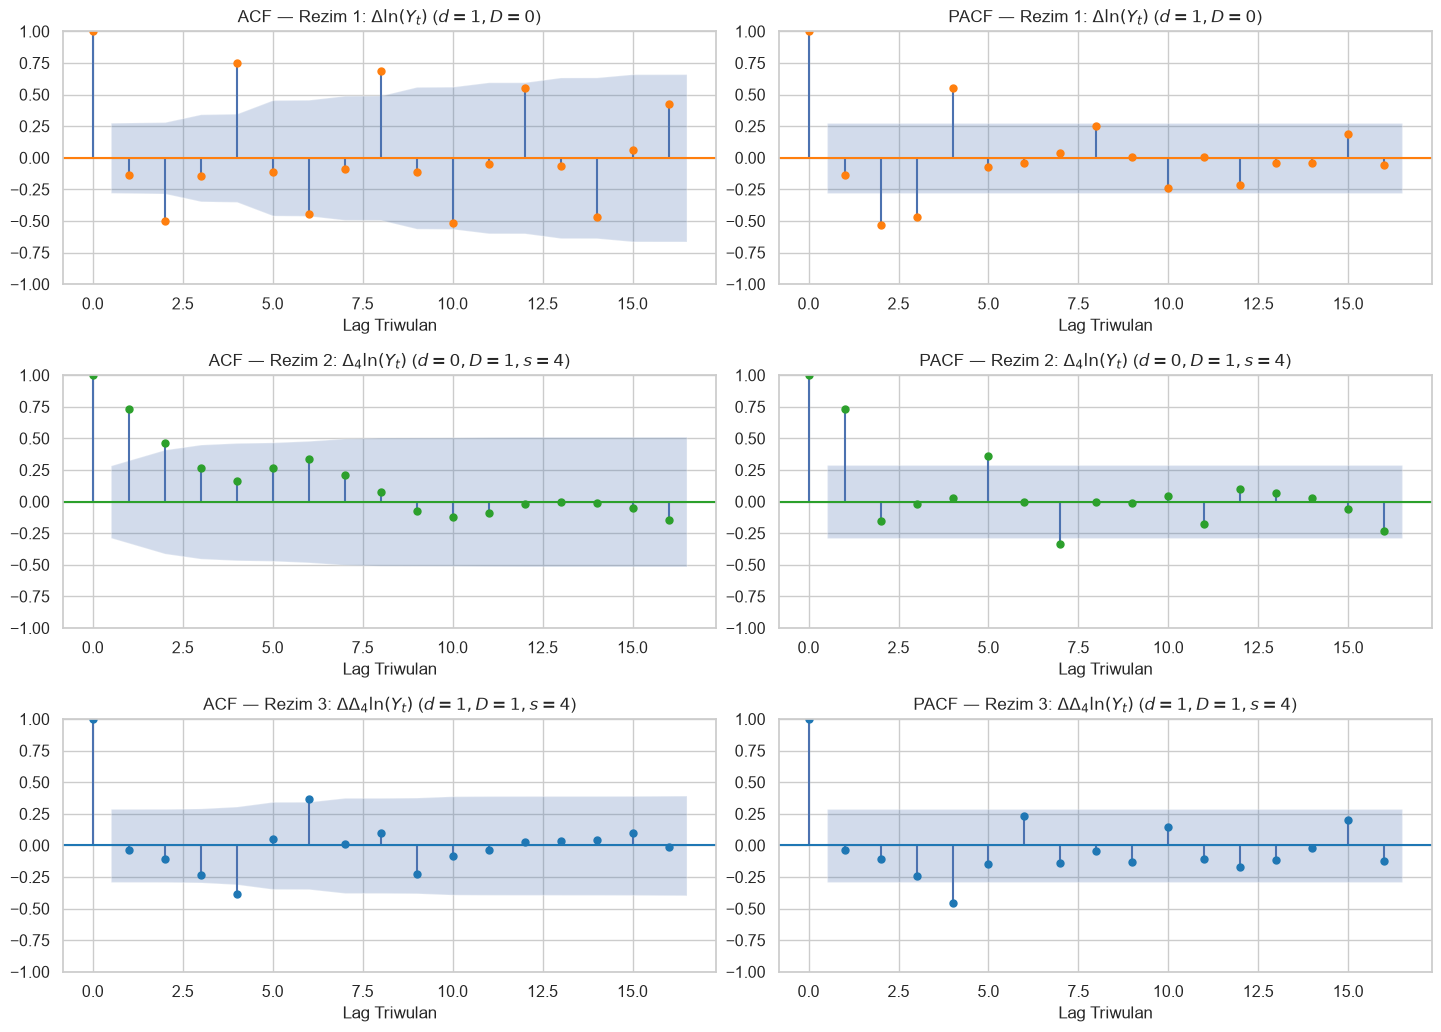

In [3]:
acf_series_list = [
    (r'Rezim 1: $\Delta\ln(Y_t)$ ($d=1, D=0$)', 'Rezim 1: Δln(Y_t) (d=1, D=0)', s_log.diff(1).dropna(), '#ff7f0e'),
    (r'Rezim 2: $\Delta_4\ln(Y_t)$ ($d=0, D=1, s=4$)', 'Rezim 2: Δ4ln(Y_t) (d=0, D=1, s=4)', s_log.diff(4).dropna(), '#2ca02c'),
    (r'Rezim 3: $\Delta\Delta_4\ln(Y_t)$ ($d=1, D=1, s=4$)', 'Rezim 3: ΔΔ4ln(Y_t) (d=1, D=1, s=4)', s_log.diff(4).diff(1).dropna(), '#1f77b4'),
]

fig, axes = plt.subplots(3, 2, figsize=(14.5, 10.5))
for row_idx, (label_plot, label_txt, ser, color) in enumerate(acf_series_list):
    plot_acf(ser.values, lags=16, ax=axes[row_idx, 0], color=color,
             title=f'ACF — {label_plot}')
    plot_pacf(ser.values, lags=16, ax=axes[row_idx, 1], color=color, method='ywm',
              title=f'PACF — {label_plot}')
    axes[row_idx, 0].set_xlabel('Lag Triwulan')
    axes[row_idx, 1].set_xlabel('Lag Triwulan')

    # Ringkasan numerik lag signifikan (|r| > 1.96 / sqrt(n))
    a_vals = acf(ser.values, nlags=12)
    p_vals = pacf(ser.values, nlags=12, method='ywm')
    bound = 1.96 / np.sqrt(len(ser))
    sig_acf = [f'lag {k} ({a_vals[k]:+.3f})' for k in range(1, 13) if abs(a_vals[k]) > bound]
    sig_pacf = [f'lag {k} ({p_vals[k]:+.3f})' for k in range(1, 13) if abs(p_vals[k]) > bound]
    print(f'{label_txt} (n={len(ser)}, batas 95% = ±{bound:.3f})')
    print(f'  ACF signifikan  : {", ".join(sig_acf) if sig_acf else "Tidak ada"}')
    print(f'  PACF signifikan : {", ".join(sig_pacf) if sig_pacf else "Tidak ada"}\n')

plt.tight_layout()
plt.show()

**Interpretasi Box-Jenkins (ACF & PACF Pasca-Diferensiasi):**
1. **Rezim 1 — $\Delta\ln(Y_t)$ ($d=1, D=0$):**
   - **ACF** memperlihatkan puncak musiman positif yang sangat kuat pada kelipatan 4: lag 4 (`+0,753`), lag 8 (`+0,684`), dan lag 12 (`+0,551`) yang meluruh perlahan, sementara **PACF** melonjak tajam pada lag 4 (`+0,551`) lalu melemah di lag 8 (`+0,248`, tidak signifikan).
   - Pola ini mengarahkan kandidat parsimoni **`SARIMA(0,1,0)(1,0,0)_4 + drift`**, **`SARIMA(0,1,0)(2,0,0)_4 + drift`**, dan **`SARIMA(0,1,0)(1,0,1)_4 + drift`**, serta varian non-musiman kecil `(1,1,0)` / `(0,1,1)` untuk diuji.
2. **Rezim 2 — $\Delta_4\ln(Y_t)$ ($d=0, D=1, s=4$):**
   - **ACF** meluruh secara geometris pada lag non-musiman awal: lag 1 (`+0,730`), lag 2 (`+0,461`), lag 3 (`+0,269`), sedangkan **PACF** terpotong tajam (*cuts off*) setelah lag 1 (`+0,730`; lag 2 = `-0,154` sudah tidak signifikan).
   - Ini adalah ciri klasik proses **AR(1)** pada deret terdiferensiasi musiman $\Rightarrow$ kandidat utama **`SARIMA(1,0,0)(1,1,0)_4 + drift`** dan **`SARIMA(1,0,0)(0,1,1)_4 + drift`**.
3. **Rezim 3 — $\Delta\Delta_4\ln(Y_t)$ ($d=1, D=1, s=4$):**
   - Lag non-musiman 1–3 tidak signifikan pada ACF maupun PACF (`p = 0, q = 0`), sedangkan pada lag musiman 4 muncul lonjakan negatif signifikan baik di **ACF (`-0,382`)** maupun **PACF (`-0,452`)**.
   - Pola ini mengindikasikan kandidat klasik **`SARIMA(0,1,0)(1,1,0)_4`** dan **`SARIMA(0,1,0)(0,1,1)_4`** (serta tambahan ringan `(0,1,1)(0,1,1)_4` / `(1,1,0)(0,1,1)_4` sebagai pembanding). Catatan penting: terdapat lonjakan positif di lag 6 (`ACF = +0,365`) yang patut dipantau pada uji diagnostik residual *Ljung-Box*.

---
## 4. Estimasi & Seleksi Kandidat Model SARIMA dan RegARIMA (Training Set)

Seluruh kandidat diestimasi dengan *Maximum Likelihood Estimation* (MLE) murni pada *Training Set* (`2010-Q1`–`2022-Q3`, $N = 51$) dengan syarat stasioneritas & invertibilitas ditegakkan (`enforce_stationarity=True`, `enforce_invertibility=True`). Evaluasi meliputi:
1. **Perbandingan Skala Asli ($Y_t$) vs Skala Logaritma ($\ln Y_t$):** Membuktikan secara empiris kebutuhan transformasi logaritma untuk menstabilkan varians dan menghasilkan residual *white noise*.
2. **Seleksi Kandidat per Rezim Diferensiasi:** Menggunakan **AIC**, **AICc** (*corrected AIC* untuk sampel kecil $N \approx 50$), dan **BIC** secara terpisah di dalam setiap rezim $(d, D)$.
3. **Uji Efek Kalender Ramadan (`RegARIMA`):** Menambahkan peubah eksogen deterministik `hari_ramadan_idul_fitri` pada kandidat terbaik tiap rezim untuk menguji apakah efek pergeseran hari raya secara statistik signifikan memperbaiki *fit* di *Training Set*.

> **Catatan Teknis Diagnostik:** Untuk menghindari distorsi *diffuse initialization* pada observasi awal filter Kalman, seluruh uji diagnostik residual (Ljung-Box dengan penyesuaian derajat bebas `model_df = p + q + P + Q`, Shapiro-Wilk, Jarque-Bera, dan Engle's ARCH-LM lag 4) dihitung pada residual efektif setelah *burn-in* `d + s*D` observasi awal.

In [4]:
candidate_specs = [
    # Pembanding Skala Asli (Y_t) — untuk verifikasi kebutuhan transformasi logaritma
    ('Skala Asli (Y_t)', 'SARIMA(0,1,0)(1,0,0)_4 + drift [Asli]', (0, 1, 0), (1, 0, 0, 4), 'c', False, False),
    ('Skala Asli (Y_t)', 'SARIMA(0,1,0)(0,1,1)_4 [Asli]',         (0, 1, 0), (0, 1, 1, 4), 'n', False, False),

    # Rezim 1: Logaritma, d=1, D=0, trend='c' (drift)
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(1,0,0)_4 + drift',           (0, 1, 0), (1, 0, 0, 4), 'c', True, False),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(2,0,0)_4 + drift',           (0, 1, 0), (2, 0, 0, 4), 'c', True, False),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(1,0,1)_4 + drift',           (0, 1, 0), (1, 0, 1, 4), 'c', True, False),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,1)(1,0,1)_4 + drift',           (0, 1, 1), (1, 0, 1, 4), 'c', True, False),
    ('Rezim 1: Log (d=1, D=0)', 'RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram',   (0, 1, 0), (1, 0, 0, 4), 'c', True, True),
    ('Rezim 1: Log (d=1, D=0)', 'RegARIMA(0,1,0)(2,0,0)_4 + drift + Ram',   (0, 1, 0), (2, 0, 0, 4), 'c', True, True),
    ('Rezim 1: Log (d=1, D=0)', 'RegARIMA(0,1,0)(1,0,1)_4 + drift + Ram',   (0, 1, 0), (1, 0, 1, 4), 'c', True, True),

    # Rezim 2: Logaritma, d=0, D=1, trend='c' (drift)
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(1,1,0)_4 + drift',           (1, 0, 0), (1, 1, 0, 4), 'c', True, False),
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(0,1,1)_4 + drift',           (1, 0, 0), (0, 1, 1, 4), 'c', True, False),
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(0,1,0)_4 + drift',           (1, 0, 0), (0, 1, 0, 4), 'c', True, False),
    ('Rezim 2: Log (d=0, D=1)', 'RegARIMA(1,0,0)(1,1,0)_4 + drift + Ram',   (1, 0, 0), (1, 1, 0, 4), 'c', True, True),
    ('Rezim 2: Log (d=0, D=1)', 'RegARIMA(1,0,0)(0,1,1)_4 + drift + Ram',   (1, 0, 0), (0, 1, 1, 4), 'c', True, True),

    # Rezim 3: Logaritma, d=1, D=1, trend='n' (tanpa drift)
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,0)(1,1,0)_4',                   (0, 1, 0), (1, 1, 0, 4), 'n', True, False),
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,0)(0,1,1)_4',                   (0, 1, 0), (0, 1, 1, 4), 'n', True, False),
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,1)(0,1,1)_4',                   (0, 1, 1), (0, 1, 1, 4), 'n', True, False),
    ('Rezim 3: Log (d=1, D=1)', 'RegARIMA(0,1,0)(0,1,1)_4 + Ram',           (0, 1, 0), (0, 1, 1, 4), 'n', True, True),
]

fitted_models = {}
summary_rows = []

for regime, name, order, sorder, trend, use_log, use_exog in candidate_specs:
    endog = log_y_train if use_log else y_train
    ex_tr = exog_train if use_exog else None
    mod = SARIMAX(
        endog,
        exog=ex_tr,
        order=order,
        seasonal_order=sorder,
        trend=trend,
        enforce_stationarity=True,
        enforce_invertibility=True,
    )
    res = mod.fit(disp=False, maxiter=500)
    burn = order[1] + sorder[1] * sorder[3]
    resid_eff = np.asarray(res.resid)[burn:]
    n_eff = len(resid_eff)
    k = len(res.params)
    aicc = float(res.aic + (2 * k * (k + 1)) / max(n_eff - k - 1, 1))

    n_arma = order[0] + order[2] + sorder[0] + sorder[2]
    lb = acorr_ljungbox(resid_eff, lags=[4, 8, 12], model_df=n_arma, return_df=True)
    lb4_p, lb8_p, lb12_p = [float(x) for x in lb['lb_pvalue'].values]
    sw_p = float(stats.shapiro(resid_eff)[1])
    jb_p = float(stats.jarque_bera(resid_eff)[1])
    arch_p = float(het_arch(resid_eff, nlags=4)[1])

    diag_pass = (lb4_p >= 0.05) and (lb8_p >= 0.05) and (lb12_p >= 0.05) and (sw_p >= 0.05) and (arch_p >= 0.05)

    exog_p = np.nan
    if use_exog:
        ex_idx = list(res.param_names).index('hari_ramadan_idul_fitri')
        exog_p = round(float(np.asarray(res.pvalues)[ex_idx]), 4)

    fitted_models[name] = {
        'res': res,
        'regime': regime,
        'order': order,
        'sorder': sorder,
        'trend': trend,
        'use_log': use_log,
        'use_exog': use_exog,
        'burn': burn,
        'resid_eff': resid_eff,
        'aicc': aicc,
        'diag_pass': diag_pass,
    }

    summary_rows.append({
        'Rezim': regime,
        'Kandidat Model': name,
        'k': k,
        'AIC': round(float(res.aic), 2),
        'AICc': round(aicc, 2),
        'BIC': round(float(res.bic), 2),
        'p(Ramadan)': exog_p,
        'LB(4) p': round(lb4_p, 4),
        'LB(8) p': round(lb8_p, 4),
        'LB(12) p': round(lb12_p, 4),
        'SW p': round(sw_p, 4),
        'JB p': round(jb_p, 4),
        'ARCH(4) p': round(arch_p, 4),
        'Lolos Diagnostik': 'YA' if diag_pass else 'TIDAK',
    })

candidates_df = pd.DataFrame(summary_rows)
print('=== Ringkasan Estimasi & Uji Diagnostik Seluruh Kandidat (Training Set, N = 51) ===')
display(candidates_df)

=== Ringkasan Estimasi & Uji Diagnostik Seluruh Kandidat (Training Set, N = 51) ===


,Rezim,Kandidat Model,k,AIC,AICc,BIC,p(Ramadan),LB(4) p,LB(8) p,LB(12) p,SW p,JB p,ARCH(4) p,Lolos Diagnostik
0,Skala Asli (Y_t),"SARIMA(0,1,0)(1,0,0)_4 + drift [Asli]",3,1005.10,1005.62,1010.83,NaN,0.0000,0.0000,0.0000,0.3048,0.4921,0.0328,TIDAK
1,Skala Asli (Y_t),"SARIMA(0,1,0)(0,1,1)_4 [Asli]",2,881.14,881.42,884.80,NaN,0.0104,0.0050,0.0057,0.1865,0.4125,0.1985,TIDAK
2,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(1,0,0)_4 + drift",3,-231.50,-230.98,-225.76,NaN,0.1320,0.1079,0.1037,0.2128,0.2185,0.6727,YA
3,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(2,0,0)_4 + drift",4,-234.96,-234.07,-227.31,NaN,0.1752,0.1800,0.2795,0.1716,0.1768,0.8778,YA
4,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(1,0,1)_4 + drift",4,-234.12,-233.23,-226.47,NaN,0.1759,0.1063,0.1686,0.2389,0.1950,0.9167,YA
5,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,1)(1,0,1)_4 + drift",5,-233.47,-232.11,-223.91,NaN,0.0709,0.1401,0.1601,0.3528,0.1083,0.7209,YA
6,"Rezim 1: Log (d=1, D=0)","RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram",4,-228.90,-228.01,-221.25,0.9979,0.0644,0.0553,0.0763,0.2475,0.2886,0.5512,YA
7,"Rezim 1: Log (d=1, D=0)","RegARIMA(0,1,0)(2,0,0)_4 + drift + Ram",5,-232.18,-230.81,-222.62,0.6696,0.2085,0.2416,0.3953,0.4601,0.3072,0.9225,YA
8,"Rezim 1: Log (d=1, D=0)","RegARIMA(0,1,0)(1,0,1)_4 + drift + Ram",5,-232.28,-230.92,-222.72,0.7295,0.2183,0.1865,0.2599,0.3174,0.2549,0.9146,YA
9,"Rezim 2: Log (d=0, D=1)","SARIMA(1,0,0)(1,1,0)_4 + drift",4,-224.52,-223.57,-217.12,NaN,0.4872,0.0878,0.1883,0.9437,0.6852,0.7884,YA


**Analisis Hasil Estimasi & Seleksi Kandidat (Training Set):**
1. **Keunggulan Mutlak Transformasi Logaritma ($\ln Y_t$):** Kedua pembanding pada skala asli ($Y_t$) gagal total pada uji *Ljung-Box* (`p <= 0,0104` hingga `0,0000`), membuktikan bahwa tanpa transformasi logaritma, dinamika pertumbuhan dan musiman multiplikatif menyisakan autokorelasi residual yang signifikan.
2. **Kandidat Terbaik di Masing-Masing Rezim Logaritma (perbandingan AICc/BIC *intra-rezim*):**
   - **Rezim 1 ($d=1, D=0$ + *drift*):** `SARIMA(0,1,0)(2,0,0)_4 + drift` memperoleh AICc (`-234,07`) dan BIC (`-227,31`) terendah, diikuti rapat oleh `SARIMA(0,1,0)(1,0,1)_4 + drift` (`AICc = -233,23`) dan model paling parsimoni `SARIMA(0,1,0)(1,0,0)_4 + drift` (`AICc = -230,98`, `BIC = -225,76`, hanya 3 parameter termasuk $\sigma^2$). Seluruh model utama Rezim 1 **lolos penuh seluruh uji diagnostik**.
   - **Rezim 2 ($d=0, D=1$ + *drift*):** `SARIMA(1,0,0)(1,1,0)_4 + drift` menjadi yang terbaik di rezim ini (`AICc = -223,57`, `BIC = -217,12`), diikuti `SARIMA(1,0,0)(0,1,1)_4 + drift` (`AICc = -223,13`). Keduanya **lolos penuh seluruh uji diagnostik** dengan normalitas residual sangat baik (`SW p = 0,9437` dan `0,8663`).
   - **Rezim 3 ($d=1, D=1$):** `SARIMA(0,1,0)(1,1,0)_4` (`AICc = -220,36`) dan `SARIMA(0,1,0)(0,1,1)_4` (`AICc = -220,00`) merupakan kandidat paling parsimoni, namun keduanya sedikit tidak lolos *Ljung-Box* pada lag 8 dan 12 (`LB(8) p = 0,0257` dan `0,0138`) akibat sisa korelasi lag-6 pasca-diferensiasi ganda.
3. **Temuan Penting pada RegARIMA (`+ hari_ramadan_idul_fitri`):** Pada seluruh rezim diferensiasi, koefisien linier variabel eksogen `hari_ramadan_idul_fitri` **tidak signifikan secara statistik** (`p = 0,4858` hingga `0,9979`) dan justru menaikkan nilai AICc serta BIC karena penambahan penalti parameter tanpa kenaikan *log-likelihood* yang berarti. Secara substantif, hal ini masuk akal karena selama periode latih (`2010-Q1`–`2022-Q3`), Ramadan hanya berpindah di rentang **Q2–Q3** (yang sudah diserap oleh komponen musiman kuartalan $s=4$), sedangkan pergeseran Ramadan masuk ke **Q1** baru dimulai pada `2023-Q1` (periode validasi). Oleh karena itu, model **SARIMA murni** lebih parsimoni, sementara RegARIMA tetap diikutkan pada evaluasi validasi untuk pembuktian empiris *out-of-sample*.

---
## 5. Uji Diagnostik Residual Mendalam pada Model Finalis

Sebelum melakukan evaluasi validasi, kita memeriksa estimasi parameter (koefisien, *standard error*, statistik-$z$, $p$-value, dan stabilitas akar polinomial AR/MA) serta visualisasi diagnostik residual untuk kandidat finalis terbaik dari rezim yang lolos diagnostik:
- **`SARIMA(0,1,0)(1,0,0)_4 + drift`** (Rezim 1 — paling parsimoni)
- **`SARIMA(0,1,0)(2,0,0)_4 + drift`** (Rezim 1 — AICc & BIC terendah di Rezim 1)
- **`SARIMA(1,0,0)(1,1,0)_4 + drift`** (Rezim 2 — AICc & BIC terendah di Rezim 2)

=== Estimasi Parameter & Stabilitas Akar AR pada Model Finalis ===


,Model,Parameter,Estimasi,Std. Error,z-Stat,p-value,Min |Akar AR|
0,"SARIMA(0,1,0)(1,0,0)_4 + drift",intercept,0.003521,0.003176,1.109,0.2675,1.057
1,"SARIMA(0,1,0)(1,0,0)_4 + drift",ar.S.L4,0.800539,0.086116,9.296,0.0000,1.057
2,"SARIMA(0,1,0)(1,0,0)_4 + drift",sigma2,0.000467,0.000094,4.978,0.0000,1.057
3,"SARIMA(0,1,0)(2,0,0)_4 + drift",intercept,0.002385,0.002783,0.857,0.3913,1.027
4,"SARIMA(0,1,0)(2,0,0)_4 + drift",ar.S.L4,0.525338,0.133865,3.924,0.0001,1.027
5,"SARIMA(0,1,0)(2,0,0)_4 + drift",ar.S.L8,0.335730,0.138574,2.423,0.0154,1.027
6,"SARIMA(0,1,0)(2,0,0)_4 + drift",sigma2,0.000412,0.000075,5.473,0.0000,1.027
7,"SARIMA(1,0,0)(1,1,0)_4 + drift",intercept,0.015027,0.010056,1.494,0.1351,1.198
8,"SARIMA(1,0,0)(1,1,0)_4 + drift",ar.L1,0.835043,0.093724,8.910,0.0000,1.198
9,"SARIMA(1,0,0)(1,1,0)_4 + drift",ar.S.L4,-0.353523,0.132854,-2.661,0.0078,1.198


Pertumbuhan log kuartalan implisit SARIMA(0,1,0)(1,0,0)_4 + drift: mu = c / (1 - Phi_1) = 0.003521 / (1 - 0.8005) = 0.01765 (≈ 1.78% q-o-q atau 7.32% y-o-y)


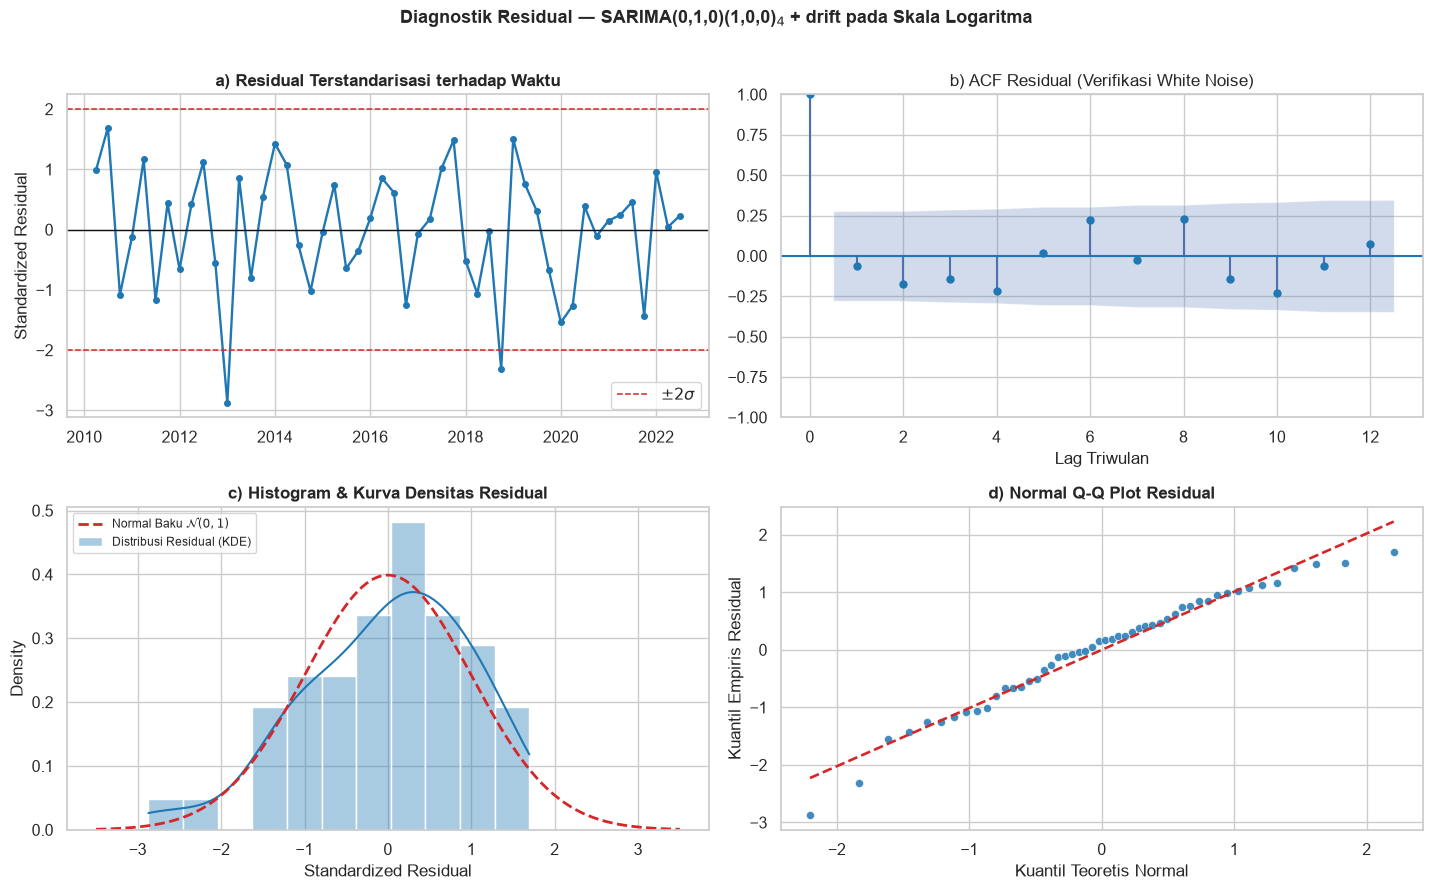

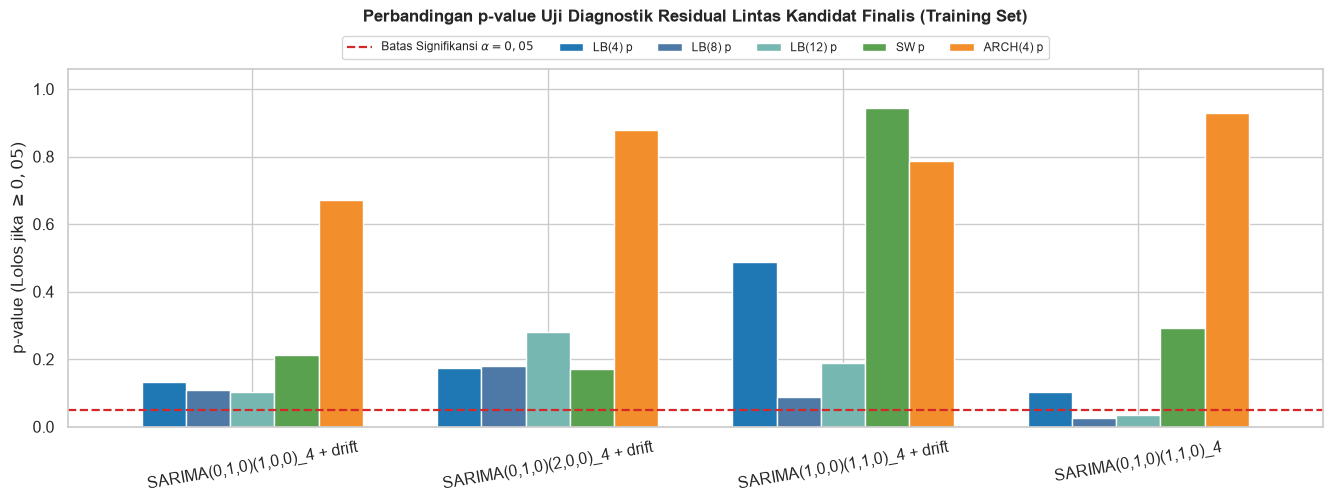

In [5]:
top_finalists = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
]

# 1. Tabel parameter & stabilitas akar polinomial AR/MA
param_rows = []
for name in top_finalists:
    res = fitted_models[name]['res']
    min_ar_root = float(np.min(np.abs(res.arroots))) if len(res.arroots) > 0 else np.nan
    for pname, coef, se, zval, pval in zip(res.param_names, res.params, res.bse, res.zvalues, res.pvalues):
        param_rows.append({
            'Model': name,
            'Parameter': pname,
            'Estimasi': round(float(coef), 6),
            'Std. Error': round(float(se), 6),
            'z-Stat': round(float(zval), 3),
            'p-value': round(float(pval), 4),
            'Min |Akar AR|': round(min_ar_root, 3) if not np.isnan(min_ar_root) else '-',
        })

param_df = pd.DataFrame(param_rows)
print('=== Estimasi Parameter & Stabilitas Akar AR pada Model Finalis ===')
display(param_df)

# Hitung rata-rata pertumbuhan kuartalan implisit pada SARIMA(0,1,0)(1,0,0)_4 + drift
res_best_pars = fitted_models['SARIMA(0,1,0)(1,0,0)_4 + drift']['res']
params_arr = np.asarray(res_best_pars.params)
c_hat = float(params_arr[0])
phi4_hat = float(params_arr[1])
implied_qoq = c_hat / (1.0 - phi4_hat)
print(
    f"Pertumbuhan log kuartalan implisit SARIMA(0,1,0)(1,0,0)_4 + drift: "
    f"mu = c / (1 - Phi_1) = {c_hat:.6f} / (1 - {phi4_hat:.4f}) = {implied_qoq:.5f} "
    f"(≈ {(np.exp(implied_qoq) - 1) * 100:.2f}% q-o-q atau {(np.exp(4 * implied_qoq) - 1) * 100:.2f}% y-o-y)"
)

# 2. Panel Diagnostik 2x2 untuk model paling parsimoni: SARIMA(0,1,0)(1,0,0)_4 + drift
info = fitted_models['SARIMA(0,1,0)(1,0,0)_4 + drift']
resid_eff = info['resid_eff']
std_resid = (resid_eff - np.mean(resid_eff)) / np.std(resid_eff, ddof=1)
dates_eff = train_df['tanggal'].iloc[info['burn']:]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.8))

# (a) Residual Terstandarisasi terhadap Waktu
axes[0, 0].plot(dates_eff, std_resid, color=PALETTE['sarima_best'], lw=1.7, marker='o', ms=4)
axes[0, 0].axhline(0, color='#111111', lw=1.0)
axes[0, 0].axhline(2, color='#d62728', ls='--', lw=1.1, label=r'$\pm 2\sigma$')
axes[0, 0].axhline(-2, color='#d62728', ls='--', lw=1.1)
axes[0, 0].set_title('a) Residual Terstandarisasi terhadap Waktu', fontweight='bold')
axes[0, 0].set_ylabel('Standardized Residual')
axes[0, 0].legend(loc='lower right')

# (b) ACF Residual
plot_acf(resid_eff, lags=12, ax=axes[0, 1], color=PALETTE['sarima_best'],
         title='b) ACF Residual (Verifikasi White Noise)')
axes[0, 1].set_xlabel('Lag Triwulan')

# (c) Histogram & KDE vs Kurva Normal
sns.histplot(std_resid, bins=11, stat='density', kde=True, color=PALETTE['sarima_best'],
             alpha=0.38, ax=axes[1, 0], label='Distribusi Residual (KDE)')
x_grid = np.linspace(-3.5, 3.5, 200)
axes[1, 0].plot(x_grid, stats.norm.pdf(x_grid), color='#d62728', ls='--', lw=2.0, label=r'Normal Baku $\mathcal{N}(0,1)$')
axes[1, 0].set_title('c) Histogram & Kurva Densitas Residual', fontweight='bold')
axes[1, 0].set_xlabel('Standardized Residual')
axes[1, 0].legend(loc='upper left', fontsize=8.8)

# (d) Normal Q-Q Plot
(osm, osr), (slope, intercept, _) = stats.probplot(std_resid, dist='norm')
axes[1, 1].scatter(osm, osr, color=PALETTE['sarima_best'], s=34, alpha=0.85, edgecolor='white', lw=0.5)
axes[1, 1].plot(osm, slope * osm + intercept, color='#d62728', lw=1.9, ls='--')
axes[1, 1].set_title('d) Normal Q-Q Plot Residual', fontweight='bold')
axes[1, 1].set_xlabel('Kuantil Teoretis Normal')
axes[1, 1].set_ylabel('Kuantil Empiris Residual')

plt.suptitle('Diagnostik Residual — SARIMA(0,1,0)(1,0,0)$_4$ + drift pada Skala Logaritma', fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# 3. Ringkasan p-value diagnostik lintas finalis (membandingkan terhadap batas alpha = 0.05)
diag_plot_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(0,1,0)(1,1,0)_4',
]
diag_sub = candidates_df[candidates_df['Kandidat Model'].isin(diag_plot_models)].set_index('Kandidat Model')
diag_sub = diag_sub.loc[diag_plot_models, ['LB(4) p', 'LB(8) p', 'LB(12) p', 'SW p', 'ARCH(4) p']]

fig, ax = plt.subplots(figsize=(13.5, 5.2))
diag_sub.plot(kind='bar', ax=ax, width=0.75,
              color=['#1f77b4', '#4e79a7', '#76b7b2', '#59a14f', '#f28e2b'])
ax.axhline(0.05, color='#d62728', ls='--', lw=1.6, label=r'Batas Signifikansi $\alpha = 0,05$')
ax.set_title('Perbandingan p-value Uji Diagnostik Residual Lintas Kandidat Finalis (Training Set)', fontweight='bold', pad=34)
ax.set_ylabel(r'p-value (Lolos jika $\geq 0,05$)')
ax.set_xlabel('')
ax.set_ylim(0, 1.06)
ax.tick_params(axis='x', rotation=10)
ax.legend(bbox_to_anchor=(0.5, 1.01), loc='lower center', ncol=6, fontsize=8.8, frameon=True)
plt.tight_layout()
plt.show()

**Analisis Diagnostik Residual Finalis:**
1. **Stabilitas & Signifikansi Parameter:**
   - Pada **`SARIMA(0,1,0)(1,0,0)_4 + drift`**, koefisien AR musiman $\Phi_1 = +0,8005$ sangat signifikan ($p < 0,0001$) dengan akar polinomial $|z| = 1,057 > 1$ (memenuhi syarat stasioneritas). Suku *intercept* ($c = +0,003521$, $p = 0,2675$) secara statistik memiliki *standard error* relatif besar karena terskala oleh $(1 - \Phi_1) \approx 0,20$ pada sampel kecil ($n = 50$), namun secara ekonomi esensial karena menghasilkan laju pertumbuhan PDB riil implisit **~1,78% q-o-q (~7,32% y-o-y)**; tanpa *drift*, proyeksi pertumbuhan akan meluruh menuju nol.
   - Pada **`SARIMA(0,1,0)(2,0,0)_4 + drift`**, kedua parameter musiman signifikan secara statistik ($\Phi_1 = +0,5253, p = 0,0001$; $\Phi_2 = +0,3357, p = 0,0154$) dengan $|z|_{\min} = 1,027 > 1$.
   - Pada **`SARIMA(1,0,0)(1,1,0)_4 + drift`**, kedua parameter AR sangat signifikan ($\phi_1 = +0,8350, p < 0,0001$; $\Phi_1 = -0,3535, p = 0,0078$) dengan $|z|_{\min} = 1,198 > 1$.
2. **Kelayakan Asumsi Residual:**
   - Panel (a)–(d) dan grafik batang *p-value* memperlihatkan bahwa ketiga model finalis dari Rezim 1 dan Rezim 2 **lolos penuh pada seluruh uji diagnostik** ($p \ge 0,05$): bebas autokorelasi (**Ljung-Box** lag 4, 8, 12), berdistribusi normal (**Shapiro-Wilk** dan **Jarque-Bera**), serta bebas heteroskedastisitas bersyarat (**ARCH-LM** lag 4).
   - Sebaliknya, model diferensiasi ganda `SARIMA(0,1,0)(1,1,0)_4` tampak memiliki batang *p-value* LB(8) dan LB(12) di bawah garis merah $\alpha = 0,05$, memperkuat keputusan bahwa diferensiasi tunggal ber-*drift* lebih sesuai untuk data ini.

---
## 6. Evaluasi Peramalan pada Validation Set (`2022-Q4`–`2024-Q3`) & Perbandingan Baseline

Karena kriteria informasi AIC/AICc/BIC tidak dapat dibandingkan langsung lintas orde diferensiasi $(d, D)$ yang berbeda, pemilihan model statistik terbaik dilakukan secara adil melalui **peramalan *multi-step* 8 triwulan ke depan** pada *Validation Set* (`2022-Q4`–`2024-Q3`) dalam satuan asli (**Miliar Rupiah**, transformasi balik $\hat{Y}_t = \exp(\widehat{\ln Y}_t)$).

Selain akurasi titik (**RMSE, MAE, MAPE, sMAPE, MASE**), kita turut memeriksa:
- **Cakupan Interval Prediksi 95% (*95% PI Coverage*):** Berapa banyak dari 8 triwulan validasi aktual yang jatuh di dalam pita ketidakpastian 95%.
- **Stabilitas Prediksi 1-Langkah (*1-Step-Ahead Filtered Check*):** Menggunakan parameter tetap dari *Training Set* (`res.apply(...)`, tanpa *refit*) untuk memastikan peringkat model konsisten baik pada horizon pendek maupun multi-langkah.

=== Perbandingan Performa Model pada Validation Set (2022-Q4 s.d. 2024-Q3, 8 Triwulan) ===


,Model,Diagnostik,RMSE (Miliar Rp),MAE (Miliar Rp),MAPE (%),sMAPE (%),MASE,95% PI Cov.,1-Step RMSE
0,"SARIMA(0,1,0)(1,0,0)_4 + drift",Lolos,3189.90,2177.65,1.023,1.033,0.235,8/8,3457.02
1,"SARIMA(0,1,0)(2,0,0)_4 + drift",Lolos,4004.44,3251.33,1.511,1.528,0.350,8/8,3508.71
2,"RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram",Lolos,4044.19,3030.57,1.416,1.433,0.327,8/8,3746.69
3,"RegARIMA(0,1,0)(1,0,1)_4 + drift + Ram",Lolos,4227.30,3458.34,1.607,1.627,0.373,8/8,3509.82
4,"SARIMA(0,1,0)(1,0,1)_4 + drift",Lolos,4261.87,3521.89,1.636,1.656,0.380,8/8,3513.16
5,"SARIMA(1,0,0)(1,1,0)_4 + drift",Lolos,4475.78,3763.61,1.735,1.735,0.406,8/8,3900.88
6,"RegARIMA(1,0,0)(1,1,0)_4 + drift + Ram",Lolos,4629.04,4151.61,1.915,1.914,0.447,8/8,3966.02
7,"SARIMA(1,0,0)(0,1,1)_4 + drift",Lolos,4807.52,4021.46,1.849,1.843,0.433,8/8,3866.54
8,"SARIMA(0,1,0)(0,1,1)_4",Tidak Lolos,6448.36,5542.14,2.568,2.613,0.597,8/8,4180.09
9,"RegARIMA(0,1,0)(0,1,1)_4 + Ram",Tidak Lolos,6474.55,5475.60,2.538,2.584,0.590,8/8,4293.6



=== Detail Peramalan per Triwulan pada Validation Set (SARIMA Terpilih vs Aktual) ===


,Periode,Ramadan (Hari),Aktual (M Rp),Naive (M Rp),SARIMA Terpilih (M Rp),Galat SARIMA (M Rp),Galat Abs. (%),PI 95% Bawah,PI 95% Atas
0,2022-Q4,0,207444.4,209604.2,200708.6,-6735.8,3.25,192388.6,209388.4
1,2023-Q1,9,206187.0,209604.2,205532.0,-655.0,0.32,193587.3,218213.7
2,2023-Q2,23,209512.8,209604.2,210048.6,535.8,0.26,195197.0,226030.1
3,2023-Q3,0,216474.8,209604.2,218627.6,2152.8,0.99,200877.7,237945.9
4,2023-Q4,0,217221.1,209604.2,211912.7,-5308.4,2.44,189093.7,237485.4
5,2024-Q1,20,218284.7,209604.2,216741.7,-1543.0,0.71,188976.9,248585.7
6,2024-Q2,12,221106.5,209604.2,221324.4,217.9,0.10,189195.1,258909.9
7,2024-Q3,0,229065.5,209604.2,229338.0,272.5,0.12,192636.3,273032.3


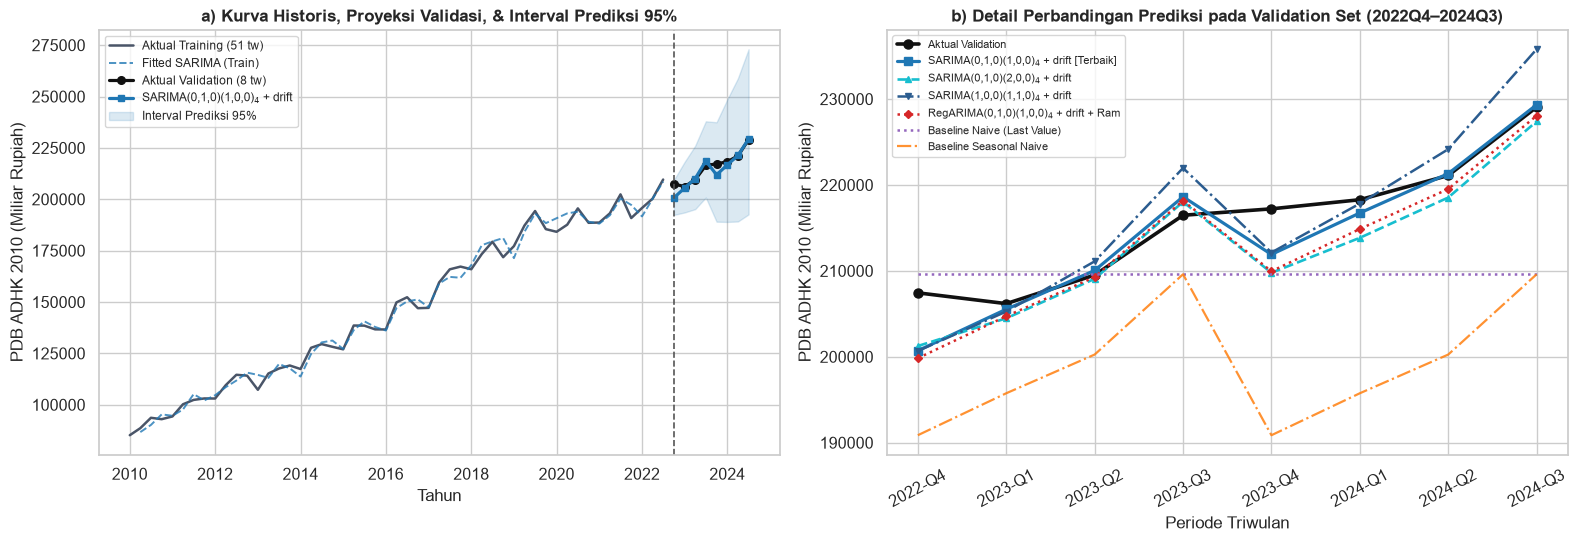

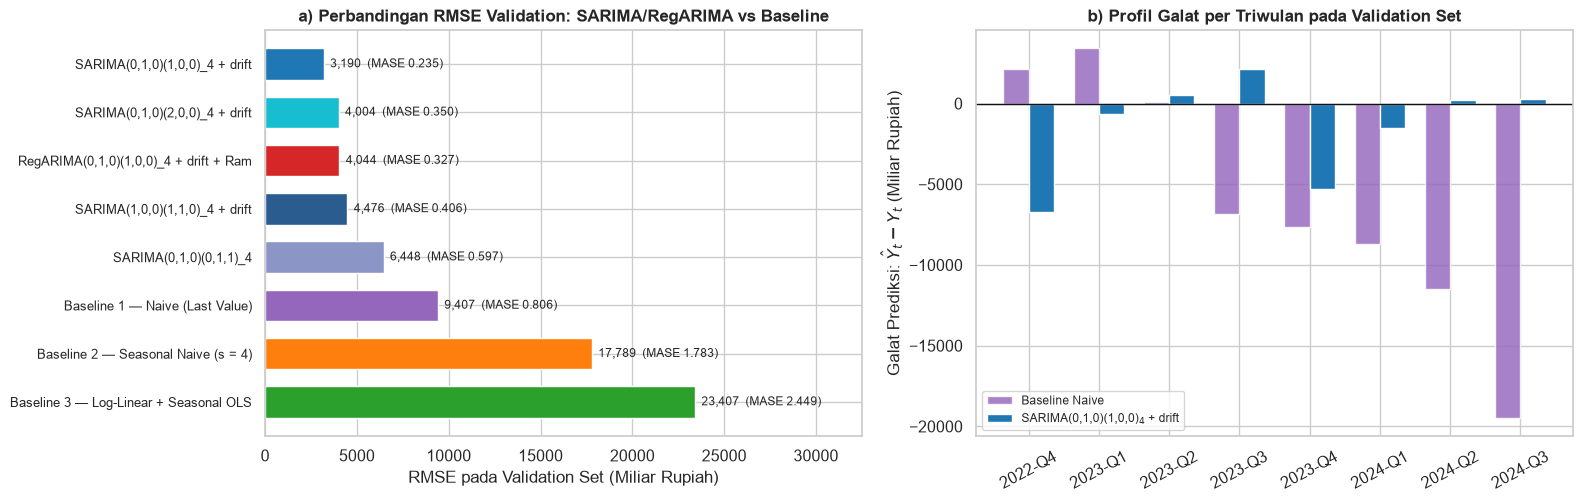

In [6]:
eval_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(0,1,0)(1,0,1)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(1,0,0)(0,1,1)_4 + drift',
    'SARIMA(0,1,0)(1,1,0)_4',
    'SARIMA(0,1,0)(0,1,1)_4',
    'RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram',
    'RegARIMA(0,1,0)(1,0,1)_4 + drift + Ram',
    'RegARIMA(1,0,0)(1,1,0)_4 + drift + Ram',
    'RegARIMA(0,1,0)(0,1,1)_4 + Ram',
]

val_rows = [
    {'Model': 'Baseline 1 — Naive (Last Value)', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_naive), '95% PI Cov.': '-', '1-Step RMSE': '-'},
    {'Model': 'Baseline 2 — Seasonal Naive (s = 4)', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_snaive), '95% PI Cov.': '-', '1-Step RMSE': '-'},
    {'Model': 'Baseline 3 — Log-Linear + Seasonal OLS', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_ols), '95% PI Cov.': '-', '1-Step RMSE': '-'},
]

val_forecasts = {}
val_cis = {}

y_tr_val_log = np.log(np.concatenate([y_train, y_val]))
ex_tr_val = pd.concat([exog_train, exog_val], ignore_index=True)

for name in eval_models:
    info = fitted_models[name]
    res = info['res']
    ex_va = exog_val if info['use_exog'] else None
    fc = res.get_forecast(steps=horizon_val, exog=ex_va)
    pred = np.exp(fc.predicted_mean)
    ci = np.exp(fc.conf_int(alpha=0.05))

    val_forecasts[name] = np.asarray(pred)
    val_cis[name] = np.asarray(ci)

    in_ci = int(np.sum((y_val >= val_cis[name][:, 0]) & (y_val <= val_cis[name][:, 1])))

    # Cek stabilitas 1-langkah (parameter latih dibekukan via .apply, tanpa refit)
    res_1step = res.apply(y_tr_val_log, exog=(ex_tr_val if info['use_exog'] else None))
    pred_1step = np.exp(np.asarray(res_1step.fittedvalues)[-horizon_val:])
    rmse_1step = float(np.sqrt(mean_squared_error(y_val, pred_1step)))

    val_rows.append({
        'Model': name,
        'Diagnostik': 'Lolos' if info['diag_pass'] else 'Tidak Lolos',
        **evaluate_forecast(y_val, val_forecasts[name]),
        '95% PI Cov.': f'{in_ci}/8',
        '1-Step RMSE': round(rmse_1step, 2),
    })

val_comparison_df = pd.DataFrame(val_rows).sort_values('RMSE (Miliar Rp)').reset_index(drop=True)
print('=== Perbandingan Performa Model pada Validation Set (2022-Q4 s.d. 2024-Q3, 8 Triwulan) ===')
display(val_comparison_df)

# Tabel detail per triwulan: Aktual vs Best SARIMA vs Best Baseline (Naive)
best_name = 'SARIMA(0,1,0)(1,0,0)_4 + drift'
best_pred = val_forecasts[best_name]
best_ci = val_cis[best_name]

quarter_detail = pd.DataFrame({
    'Periode': val_df['periode'].values,
    'Ramadan (Hari)': val_df['hari_ramadan_idul_fitri'].values,
    'Aktual (M Rp)': np.round(y_val, 1),
    'Naive (M Rp)': np.round(pred_val_naive, 1),
    'SARIMA Terpilih (M Rp)': np.round(best_pred, 1),
    'Galat SARIMA (M Rp)': np.round(best_pred - y_val, 1),
    'Galat Abs. (%)': np.round(np.abs(best_pred - y_val) / y_val * 100, 2),
    'PI 95% Bawah': np.round(best_ci[:, 0], 1),
    'PI 95% Atas': np.round(best_ci[:, 1], 1),
})
print('\n=== Detail Peramalan per Triwulan pada Validation Set (SARIMA Terpilih vs Aktual) ===')
display(quarter_detail)

# --- FIGURE 1: Kurva Historis & Zoom Perbandingan pada Validation Set ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))

# Panel (a): Historis Training + Proyeksi Validation + 95% PI
res_best = fitted_models[best_name]['res']
fitted_train_best = np.exp(np.asarray(res_best.fittedvalues)[1:])  # skip t=0 diffuse init
axes[0].plot(train_df['tanggal'], y_train, color=PALETTE['train'], lw=1.8, label='Aktual Training (51 tw)')
axes[0].plot(train_df['tanggal'].iloc[1:], fitted_train_best, color=PALETTE['sarima_best'], ls='--', lw=1.4, alpha=0.8, label='Fitted SARIMA (Train)')
axes[0].plot(val_df['tanggal'], y_val, color=PALETTE['actual'], marker='o', ms=5.5, lw=2.3, label='Aktual Validation (8 tw)')
axes[0].plot(val_df['tanggal'], best_pred, color=PALETTE['sarima_best'], marker='s', ms=5, lw=2.3, label='SARIMA(0,1,0)(1,0,0)$_4$ + drift')
axes[0].fill_between(val_df['tanggal'], best_ci[:, 0], best_ci[:, 1], color=PALETTE['sarima_best'], alpha=0.16, label='Interval Prediksi 95%')
axes[0].axvline(val_df['tanggal'].iloc[0], color='#555555', ls='--', lw=1.2)
axes[0].set_title('a) Kurva Historis, Proyeksi Validasi, & Interval Prediksi 95%', fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[0].legend(loc='upper left', fontsize=8.4)

# Panel (b): Zoom Validation Set (8 Triwulan)
x_periods = val_df['periode'].values
axes[1].plot(x_periods, y_val, color=PALETTE['actual'], marker='o', ms=6.5, lw=2.6, label='Aktual Validation')
axes[1].plot(x_periods, best_pred, color=PALETTE['sarima_best'], marker='s', ms=5.5, lw=2.3, label='SARIMA(0,1,0)(1,0,0)$_4$ + drift [Terbaik]')
axes[1].plot(x_periods, val_forecasts['SARIMA(0,1,0)(2,0,0)_4 + drift'], color=PALETTE['sarima_alt1'], ls='--', marker='^', ms=5, lw=1.9, label='SARIMA(0,1,0)(2,0,0)$_4$ + drift')
axes[1].plot(x_periods, val_forecasts['SARIMA(1,0,0)(1,1,0)_4 + drift'], color=PALETTE['sarima_alt2'], ls='-.', marker='v', ms=5, lw=1.8, label='SARIMA(1,0,0)(1,1,0)$_4$ + drift')
axes[1].plot(x_periods, val_forecasts['RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram'], color=PALETTE['regarima'], ls=':', marker='D', ms=4.5, lw=1.8, label='RegARIMA(0,1,0)(1,0,0)$_4$ + drift + Ram')
axes[1].plot(x_periods, pred_val_naive, color=PALETTE['naive'], ls=':', lw=1.8, label='Baseline Naive (Last Value)')
axes[1].plot(x_periods, pred_val_snaive, color=PALETTE['snaive'], ls='-.', lw=1.6, alpha=0.85, label='Baseline Seasonal Naive')
axes[1].set_title('b) Detail Perbandingan Prediksi pada Validation Set (2022Q4–2024Q3)', fontweight='bold')
axes[1].set_xlabel('Periode Triwulan')
axes[1].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[1].tick_params(axis='x', rotation=28)
axes[1].legend(loc='upper left', fontsize=8.0)

plt.tight_layout()
plt.show()

# --- FIGURE 2: Perbandingan RMSE & Galat per Kuartal ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

# Panel (a): Bar chart RMSE Validation (Model Utama vs Baseline)
bar_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'RegARIMA(0,1,0)(1,0,0)_4 + drift + Ram',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(0,1,0)(0,1,1)_4',
    'Baseline 1 — Naive (Last Value)',
    'Baseline 2 — Seasonal Naive (s = 4)',
    'Baseline 3 — Log-Linear + Seasonal OLS',
]
bar_df = val_comparison_df[val_comparison_df['Model'].isin(bar_models)].set_index('Model').loc[bar_models]
bar_colors = [
    PALETTE['sarima_best'], PALETTE['sarima_alt1'], PALETTE['regarima'],
    PALETTE['sarima_alt2'], '#8c96c6', PALETTE['naive'], PALETTE['snaive'], PALETTE['ols'],
]
y_pos = np.arange(len(bar_df))
bars = axes[0].barh(y_pos, bar_df['RMSE (Miliar Rp)'].values, color=bar_colors, height=0.65)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(bar_df.index, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel('RMSE pada Validation Set (Miliar Rupiah)')
axes[0].set_title('a) Perbandingan RMSE Validation: SARIMA/RegARIMA vs Baseline', fontweight='bold')
axes[0].set_xlim(0, 32500)
for bar, rmse_v, mase_v in zip(bars, bar_df['RMSE (Miliar Rp)'].values, bar_df['MASE'].values):
    axes[0].text(rmse_v + 350, bar.get_y() + bar.get_height() / 2,
                 f'{rmse_v:,.0f}  (MASE {mase_v:.3f})', va='center', fontsize=8.4)

# Panel (b): Galat Peramalan per Kuartal (Prediksi - Aktual)
err_sarima = best_pred - y_val
err_naive = pred_val_naive - y_val
x_idx = np.arange(len(x_periods))
w = 0.36
axes[1].bar(x_idx - w / 2, err_naive, width=w, color=PALETTE['naive'], alpha=0.82, label='Baseline Naive')
axes[1].bar(x_idx + w / 2, err_sarima, width=w, color=PALETTE['sarima_best'], label='SARIMA(0,1,0)(1,0,0)$_4$ + drift')
axes[1].axhline(0, color='#111111', lw=1.0)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(x_periods, rotation=28)
axes[1].set_ylabel(r'Galat Prediksi: $\hat{Y}_t - Y_t$ (Miliar Rupiah)')
axes[1].set_title('b) Profil Galat per Triwulan pada Validation Set', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8.8)

plt.tight_layout()
plt.show()

**Analisis Evaluasi Validation Set (`2022-Q4`–`2024-Q3`):**
1. **Keunggulan Tegas Model Statistik atas Seluruh Baseline:** Seluruh kandidat SARIMA & RegARIMA pada skala logaritma berhasil melampaui ketiga *baseline* awal secara telak pada seluruh metrik (`RMSE`, `MAE`, `MAPE`, `sMAPE`, dan `MASE`).
2. **Model Statistik Terpilih — `SARIMA(0,1,0)(1,0,0)_4 + drift` pada $\ln(Y_t)$:**
   - Mencapai kinerja **terbaik** di antara seluruh kandidat pada horizon validasi 8 triwulan: **`RMSE = 3.189,90` miliar rupiah**, **`MAE = 2.177,65` miliar rupiah**, **`MAPE = 1,023%`**, **`sMAPE = 1,033%`**, dan **`MASE = 0,235`**.
   - Menurunkan RMSE sebesar **66,1%** dibanding *baseline* terbaik (**Naive**: `9.407,24` miliar rupiah) dan **82,1%** dibanding **Seasonal Naive** (`17.789,37` miliar rupiah).
   - Konsisten menjadi peringkat pertama pula pada pemeriksaan **1-step-ahead** (`RMSE = 3.457,02` miliar rupiah), lolos penuh seluruh uji diagnostik residual, paling parsimoni (3 parameter), serta memiliki cakupan interval prediksi 95% sempurna (**8/8 triwulan aktual** berada di dalam pita 95%).
3. **Perbandingan Lintas Rezim & RegARIMA:**
   - **Rezim 1 ($d=1, D=0$ + *drift*):** `SARIMA(0,1,0)(2,0,0)_4 + drift` menempati posisi kedua (`RMSE = 4.004,44`; `MASE = 0,350`), diikuti `SARIMA(0,1,0)(1,0,1)_4 + drift` (`RMSE = 4.261,87`; `MASE = 0,380`).
   - **Rezim 2 ($d=0, D=1$ + *drift*):** `SARIMA(1,0,0)(1,1,0)_4 + drift` sangat kompetitif (`RMSE = 4.475,78`; `MASE = 0,406`) dan lolos diagnostik dengan sangat baik, sehingga layak dicatat sebagai alternatif kuat.
   - **Rezim 3 ($d=1, D=1$):** `SARIMA(0,1,0)(0,1,1)_4` (`RMSE = 6.448,36`; `MASE = 0,597`) dan `(0,1,0)(1,1,0)_4` (`RMSE = 6.594,23`; `MASE = 0,610`) cenderung *under-predict* karena diferensiasi ganda meneruskan pelandaian pertumbuhan era pandemi 2020–2022 secara terlalu pesimistis.
   - **RegARIMA (`+ hari_ramadan_idul_fitri`):** Konsisten dengan hasil insignifikansi parameter di *Training Set*, penambahan eksogen Ramadan secara linier tidak mengungguli SARIMA murni pada validasi (`RMSE = 4.044,19` vs `3.189,90` pada spesifikasi `(0,1,0)(1,0,0)_4 + drift`).
4. **Bedah Galat per Triwulan:** Pada `SARIMA(0,1,0)(1,0,0)_4 + drift`, akurasi pada **Q1, Q2, dan Q3** sangat presisi (galat absolut hanya **0,10%–0,99%**; misalnya `2024-Q2` hanya meleset `+217,9` miliar rupiah dan `2024-Q3` `+272,5` miliar rupiah). Dua galat terbesar terjadi di **Q4** (`2022-Q4`: `-6.735,8` M Rp / `3,25%`; `2023-Q4`: `-5.308,4` M Rp / `2,44%`), karena secara historis (`2010–2021`) Q4 lazim terkontraksi tajam dibanding Q3, sementara pasca-2022 permintaan Q4 bertahan lebih kuat. Pola non-linier dan pergeseran Ramadan ke Q1 inilah yang menarik untuk diuji menggunakan **SVR-RBF** pada tahap selanjutnya.

---
## 7. Ringkasan Progress 3

### Data Analysis Key Findings
- **Stasioneritas Pasca-Diferensiasi (*Training Set*, $N=51$):** Diferensiasi ganda $\Delta\Delta_4 \ln(Y_t)$ ($d=1, D=1, s=4$) mencapai stasioneritas penuh pada kedua uji (`ADF Stat = -6,3315, p < 0,0001`; `KPSS Stat = 0,0387, p = 0,1000`), sementara $\Delta \ln(Y_t)$ ($d=1, D=0$) lolos KPSS (`p = 0,1000`) dengan pola musiman kuartalan kuat pada lag 4, 8, dan 12 yang dapat dimodelkan oleh AR musiman stasioner ber-*drift*.
- **Kebutuhan Transformasi Logaritma:** Model pada skala asli ($Y_t$) gagal uji *white noise* Ljung-Box (`p <= 0,0104`), sedangkan model pada skala logaritma ($\ln Y_t$) di Rezim 1 ($d=1, D=0$ + *drift*) dan Rezim 2 ($d=0, D=1$ + *drift*) lolos penuh seluruh uji diagnostik residual.
- **Model Statistik Terpilih — `SARIMA(0,1,0)(1,0,0)_4 + drift` pada $\ln(Y_t)$:** Memiliki parameter musiman sangat signifikan ($\Phi_1 = +0,8005, p < 0,0001$; akar AR $|z| = 1,057 > 1$), parsimoni (3 parameter), dan **lolos seluruh uji diagnostik**: Ljung-Box lag 4 (`p = 0,1320`), lag 8 (`p = 0,1079`), lag 12 (`p = 0,1037`), Shapiro-Wilk (`p = 0,2128`), Jarque-Bera (`p = 0,2185`), serta Engle's ARCH-LM lag 4 (`p = 0,6727`).
- **Performa Validation Set (`2022-Q4`–`2024-Q3`, 8 triwulan):** `SARIMA(0,1,0)(1,0,0)_4 + drift` mencatat **`RMSE = 3.189,90` M Rp**, **`MAE = 2.177,65` M Rp**, **`MAPE = 1,023%`**, **`sMAPE = 1,033%`**, dan **`MASE = 0,235`**, dengan cakupan interval prediksi 95% sebesar **8/8 (100%)**. Kinerja ini memangkas RMSE sebesar **66,1%** dibanding *baseline* Naive (`9.407,24` M Rp, `MASE = 0,806`) dan **82,1%** dibanding Seasonal Naive (`17.789,37` M Rp, `MASE = 1,783`).
- **Uji RegARIMA (`hari_ramadan_idul_fitri`):** Efek linier hari Ramadan/Idul Fitri terbukti **tidak signifikan secara statistik** pada *Training Set* (`p = 0,4858`–`0,9979`) dan menghasilkan galat validasi lebih tinggi (`RMSE = 4.044,19` M Rp vs `3.189,90` M Rp) dibanding SARIMA murni, karena pergeseran Ramadan ke Q1 baru berlangsung mulai `2023-Q1`.

### Insights or Next Steps
- **Progress 4 (Pemodelan Pembanding SVR-RBF):** Membangun rekayasa fitur *lag* musiman (mis. lag 1, 2, 4, 5), indikator kuartal, indeks waktu, dan fitur kalender Ramadan secara ketat tanpa kebocoran data, lalu melakukan *hyperparameter tuning* (`C`, `epsilon`, `gamma`) berbasis *time-series cross-validation* untuk mengevaluasi **SVR-RBF** pada *Validation Set* yang sama (`2022-Q4`–`2024-Q3`).
- **Progress 5 & 6 (Evaluasi Final *Test Set* & Finalisasi Poster):** Setelah konfigurasi terbaik **SARIMA** dan **SVR-RBF** ditetapkan di tahap validasi, keduanya akan dilatih ulang pada gabungan `Train + Validation` (59 observasi: `2010-Q1`–`2024-Q3`) untuk perbandingan akhir *head-to-head* pada **Test Set (`2024-Q4`–`2026-Q3`)** yang hingga kini masih dikunci, lalu hasil akhir dituangkan ke Poster Ilmiah A1 (Bagian 04–07).